# Improved Pipeline — Overlapping-Window Detection and Training Augmentation

The methodology is unchanged: the same LSTM autoencoder, the same frozen validation threshold, the same DQN,
state (channel errors + investigation status + remaining budget), reward (±1) and budget (5). Two weaknesses found
in notebooks 03 and 05 are addressed:

1. **Short events were missed.** Windows were cut in fixed, non-overlapping 128-sample (3.2 h) blocks; 38 / 168 events
   were never detected, with a median duration of 2.8 h. Here the *same* model scores **overlapping windows with a
   stride of 32 samples (48 min)**, so every short anomaly gets a window positioned on it.
2. **Few training examples for rare event types.** Previously each training event contributed one state. Here
   the DQN can also train on **every detected window of each training event** (top 20 by error). Validation and
   test still use exactly one case per event (its highest-error detected window). Whether this augmentation is
   used is decided on inner-validation reward only.

Because the two pipelines investigate different numbers of events, they are also compared **end-to-end over all
168 events**: an undetected event counts as 0 relevant channels found.

In [1]:
import os, sys, json, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
import multiprocessing as mp
from scipy.stats import wilcoxon

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
import rl_utils as U
import dqn_core as D

OUT = PROJECT / "outputs"; LSTM_DIR = OUT / "05_lstm_autoencoder"; PLOTS = OUT / "04_plots"
EXT = OUT / "09_extended_experiments"; IMP = OUT / "10_improved_pipeline"; IMP.mkdir(parents=True, exist_ok=True)
SEED = 42; random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})
def save_show(name):
    plt.tight_layout(); plt.savefig(PLOTS / name, bbox_inches="tight"); plt.close()
    display(Image(filename=str(PLOTS / name)))

telemetry_df = pd.read_parquet(OUT / "02_preprocessing" / "telemetry_90s_12channels.parquet")
labels = pd.read_csv(OUT / "01_dataset" / "selected_anomaly_labels.csv", parse_dates=["StartTime", "EndTime"])
cfg_lstm = json.load(open(LSTM_DIR / "lstm_config.json"))
stats = pd.read_csv(LSTM_DIR / "training_normalization_statistics.csv")
ae = tf.keras.models.load_model(LSTM_DIR / "lstm_autoencoder.keras")
CHANNELS = list(telemetry_df.columns); N_CH = len(CHANNELS)
mu, sd = stats["Mean"].to_numpy(), stats["Std"].to_numpy()
WINDOW, CLIP, THR = cfg_lstm["window"], cfg_lstm["clip_sigma"], cfg_lstm["threshold"]
values = telemetry_df.to_numpy(np.float32); index = telemetry_df.index
event_sets = labels.groupby("ID")["Channel"].apply(set).to_dict()
EVENTS = sorted(event_sets)
print(f"Frozen threshold {THR:.6f} (unchanged from notebook 02) | events {len(EVENTS)}")

I0000 00:00:1794218067.813164    1070 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794218068.757949    1070 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Frozen threshold 0.018620 (unchanged from notebook 02) | events 168


## 1. Score overlapping windows (stride 32 = 48 min) with the unchanged LSTM autoencoder

In [2]:
STRIDE = 32
starts = np.arange(0, len(values) - WINDOW + 1, STRIDE)
nan_cs = np.concatenate([[0], np.cumsum(np.isnan(values).any(axis=1))])
ok = (nan_cs[starts + WINDOW] - nan_cs[starts]) == 0
starts = starts[ok]
errs = np.empty((len(starts), N_CH), np.float32); t0 = time.time()
for i in range(0, len(starts), 8192):
    s = starts[i:i + 8192]
    x = values[s[:, None] + np.arange(WINDOW)[None, :]]
    xn = np.clip((x - mu) / sd, -CLIP, CLIP).astype(np.float32)
    errs[i:i + 8192] = np.mean((xn - ae.predict(xn, batch_size=2048, verbose=0)) ** 2, axis=1)
overall = errs.mean(axis=1); detected = overall >= THR
print(f"Overlapping windows scored: {len(starts):,} in {(time.time()-t0)/60:.1f} min | detected: {detected.sum():,} ({detected.mean()*100:.2f} %)")

def overlaps(mask):
    cs = np.concatenate([[0], np.cumsum(mask)]); return (cs[starts + WINDOW] - cs[starts]) > 0
any_lab = overlaps(U.interval_mask(index, labels.StartTime.values, labels.EndTime.values))
print(f"Detected windows overlapping an annotation: {any_lab[detected].mean()*100:.1f} % (non-overlapping grid in notebook 03: 72.5 %)")

ev_mask = {}
for eid, g in labels.groupby("ID"):
    ev_mask[eid] = overlaps(U.interval_mask(index, g.StartTime.values, g.EndTime.values))

Overlapping windows scored: 153,312 in 0.8 min | detected: 9,716 (6.34 %)
Detected windows overlapping an annotation: 72.0 % (non-overlapping grid in notebook 03: 72.5 %)


## 2. Event coverage: non-overlapping (notebook 03) vs overlapping windows

            Old  New  Events
Split                       
Train        90   95     117
Validation   20   23      25
Test         20   20      26
Total       130  138     168

Newly detected events: 8 (median duration 14.8 h) | lost: 0
Still undetected: 30 (median duration 0.4 h)


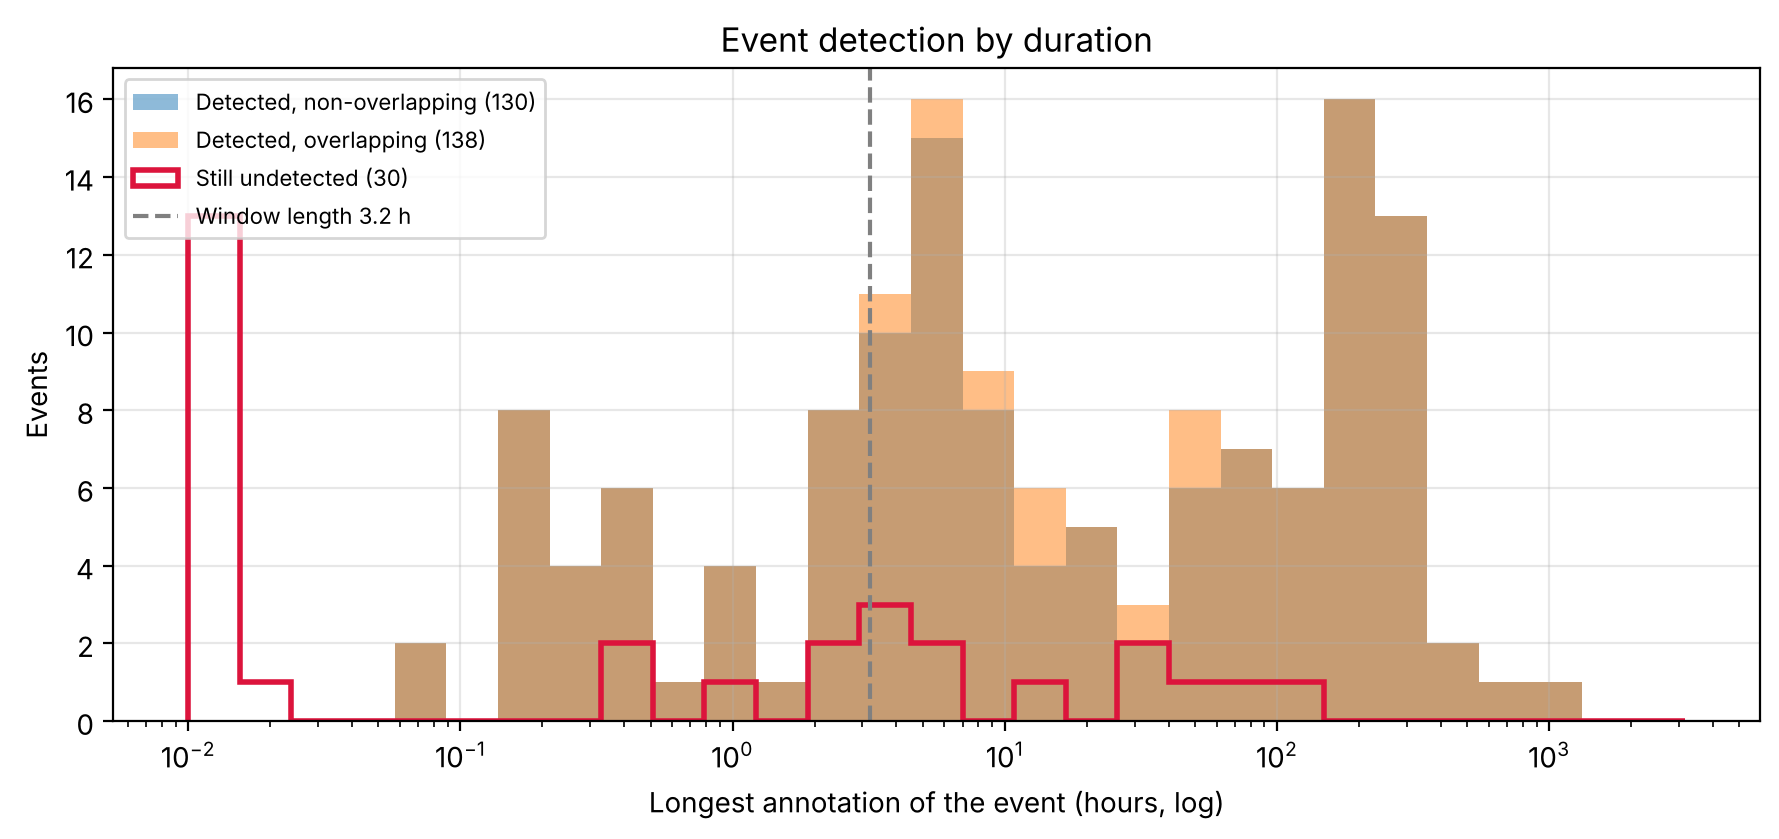

In [3]:
split_ids = pd.read_csv(OUT / "03_splits" / "anomaly_event_split.csv").set_index("ID")["Split"]
cases_old = pd.read_csv(OUT / "06_rl_dqn" / "investigation_cases.csv")
best_win, aug_win = {}, {}
for eid in EVENTS:
    c = np.where(detected & ev_mask[eid])[0]
    if len(c):
        order = c[np.argsort(-overall[c])]
        best_win[eid] = order[0]; aug_win[eid] = order[:20]
dur = labels.groupby("ID").apply(lambda g: (g.EndTime - g.StartTime).dt.total_seconds().max() / 3600, include_groups=False)
cov = pd.DataFrame({"Split": split_ids.reindex(EVENTS).values, "Old": [e in set(cases_old.EventID) for e in EVENTS],
                    "New": [e in best_win for e in EVENTS], "Duration_h": dur.reindex(EVENTS).values}, index=EVENTS)
cov_tab = cov.groupby("Split")[["Old", "New"]].sum().reindex(["Train", "Validation", "Test"])
cov_tab.loc["Total"] = cov_tab.sum(); cov_tab["Events"] = list(cov.Split.value_counts().reindex(["Train", "Validation", "Test"])) + [len(cov)]
print(cov_tab.to_string())
newly = cov[cov.New & ~cov.Old]; lost = cov[cov.Old & ~cov.New]
print(f"\nNewly detected events: {len(newly)} (median duration {newly.Duration_h.median():.1f} h) | lost: {len(lost)}")
print(f"Still undetected: {(~cov.New).sum()} (median duration {cov[~cov.New].Duration_h.median():.1f} h)")

fig, ax = plt.subplots(figsize=(9, 4.3))
bins = np.logspace(-2, 3.5, 30)
ax.hist(cov.Duration_h[cov.Old].clip(0.01), bins=bins, alpha=0.5, label=f"Detected, non-overlapping ({cov.Old.sum()})")
ax.hist(cov.Duration_h[cov.New].clip(0.01), bins=bins, alpha=0.5, label=f"Detected, overlapping ({cov.New.sum()})")
ax.hist(cov.Duration_h[~cov.New].clip(0.01), bins=bins, histtype="step", lw=2, color="crimson", label=f"Still undetected ({(~cov.New).sum()})")
ax.axvline(3.2, ls="--", color="grey", label="Window length 3.2 h"); ax.set_xscale("log")
ax.set_xlabel("Longest annotation of the event (hours, log)"); ax.set_ylabel("Events"); ax.set_title("Event detection by duration"); ax.legend(fontsize=8)
save_show("21_event_detection_overlapping_windows.png")

## 3. Cross-validation with and without training augmentation (budget 5)

In [4]:
HP = dict(hidden=64, lr=1e-3, gamma=0.95, batch=64, buffer=10000, episodes=3000, eps_start=1.0, eps_min=0.05,
          eps_decay=0.998, target_update=20, eval_every=50)
SEEDS = [0, 1, 2, 3, 4]; K = 5
CASE_EVENTS = np.array(sorted(best_win))
S_case = np.log1p(errs[[best_win[e] for e in CASE_EVENTS]])
Y_case = np.array([[ch in event_sets[e] for ch in CHANNELS] for e in CASE_EVENTS], bool)
print("Investigation cases (one per detected event):", len(CASE_EVENTS))

def train_arrays(evs, augment):
    if not augment:
        idx = [best_win[e] for e in evs]; ys = [[ch in event_sets[e] for ch in CHANNELS] for e in evs]
    else:
        idx, ys = [], []
        for e in evs:
            for w in aug_win[e]:
                idx.append(w); ys.append([ch in event_sets[e] for ch in CHANNELS])
    return np.log1p(errs[idx]), np.array(ys, bool)

def run_cv(budget, augment, tag):
    folds = [p_ for p_ in np.array_split(np.random.RandomState(SEED).permutation(len(CASE_EVENTS)), K)]
    cfgs, meta = [], []
    for k, te in enumerate(folds):
        rest = np.random.RandomState(100 + k).permutation(np.setdiff1d(np.arange(len(CASE_EVENTS)), te))
        n_va = max(1, int(round(len(rest) * 0.2))); va, tr = rest[:n_va], rest[n_va:]
        S_tr, Y_tr = train_arrays(CASE_EVENTS[tr], augment)
        meta.append((k, tr, va, te))
        for s in SEEDS:
            cfgs.append(dict(HP, budget=budget, seed=s + 1000 * k, train_scores=S_tr, train_targets=Y_tr,
                             val_scores=S_case[va], val_targets=Y_case[va], out_dir=str(IMP / "models")))
    (IMP / "models").mkdir(exist_ok=True); t0 = time.time()
    with mp.get_context("spawn").Pool(5) as pool:
        runs = pool.map(D.train_seed, cfgs)
    rows = []
    for (k, tr, va, te), i0 in zip(meta, range(0, len(runs), len(SEEDS))):
        fixed = list(np.argsort(-Y_case[np.r_[tr, va]].sum(0), kind="stable"))
        for r_ in runs[i0:i0 + len(SEEDS)]:
            q = D.build_q_network(tf); q.set_weights(r_["weights"])
            for i, m in zip(te, D.evaluate(lambda x: q(x, training=False).numpy(), S_case[te], Y_case[te], budget)):
                rows.append(dict(m, Method="DQN", Seed=r_["seed"] % 1000, Case=int(i)))
        for i in te:
            y = Y_case[i]; n = int(y.sum())
            rows.append(dict(D.episode_metrics(np.array(fixed[:budget]), y), Method="Fixed Priority", Seed=-1, Case=int(i)))
            rows.append(dict(D.episode_metrics(np.argsort(-S_case[i], kind="stable")[:budget], y), Method="LSTM-Greedy", Seed=-1, Case=int(i)))
            rows.append(dict(D.episode_metrics(np.argsort(~y, kind="stable")[:budget], y), Method="Oracle", Seed=-1, Case=int(i)))
            eh = n * budget / N_CH
            rows.append(dict(Hits=eh, Steps=budget, TotalReward=2 * eh - budget, Precision_at_5=eh / budget, Recall_at_5=eh / n,
                             UnnecessaryInvestigations=budget - eh, Method="Random", Seed=-1, Case=int(i)))
    df = pd.DataFrame(rows); df["EventID"] = CASE_EVENTS[df.Case]; df["Budget"] = budget; df["Config"] = tag
    df["N_annotated"] = Y_case.sum(1)[df.Case]
    det = df[df.Method != "Random"]; assert np.allclose(det.TotalReward, 2 * det.Hits - budget)
    df.attrs["inner_val_reward"] = float(np.mean([r_["best_val_reward"] for r_ in runs]))
    print(f"{tag} | budget {budget}: {len(CASE_EVENTS)} cases, {len(runs)} trainings in {(time.time()-t0)/60:.1f} min "
          f"| inner-validation reward {df.attrs['inner_val_reward']:.3f}")
    return df

ORDER = ["DQN", "Fixed Priority", "LSTM-Greedy", "Random", "Oracle"]
MET = ["TotalReward", "Hits", "Precision_at_5", "Recall_at_5", "UnnecessaryInvestigations"]
def summarise(df):
    out = []
    for m in ORDER:
        d = df[df.Method == m]
        if m == "DQN":
            ps = d.groupby("Seed")[MET].mean(); row = {k: ps[k].mean() for k in MET} | {f"{k}_std": ps[k].std(ddof=0) for k in MET}
        else:
            row = {k: d[k].mean() for k in MET} | {f"{k}_std": 0.0 for k in MET}
        out.append({"Method": m, "Cases": d.Case.nunique()} | row)
    return pd.DataFrame(out)

def paired_tests(df):
    dq = df[df.Method == "DQN"].groupby("Case")["Hits"].mean(); res = []; rng = np.random.RandomState(SEED)
    for o in ["Fixed Priority", "LSTM-Greedy", "Random"]:
        diff = (dq - df[df.Method == o].set_index("Case")["Hits"].reindex(dq.index)).to_numpy()
        boots = [rng.choice(diff, len(diff)).mean() for _ in range(5000)]
        res.append({"Comparison": f"DQN vs {o}", "Mean_hit_diff": diff.mean(), "CI95_low": np.percentile(boots, 2.5),
                    "CI95_high": np.percentile(boots, 97.5), "DQN_better": int((diff > 1e-9).sum()), "Equal": int((np.abs(diff) <= 1e-9).sum()),
                    "DQN_worse": int((diff < -1e-9).sum()), "Wilcoxon_p": wilcoxon(diff, zero_method="zsplit").pvalue if np.any(diff != 0) else 1.0})
    return pd.DataFrame(res)

cv_plain = run_cv(5, False, "overlapping windows")
cv_aug = run_cv(5, True, "overlapping windows + training augmentation")
CHOSEN = cv_aug if cv_aug.attrs["inner_val_reward"] > cv_plain.attrs["inner_val_reward"] else cv_plain
print("Chosen on inner validation:", CHOSEN.Config.iloc[0])
for df in [cv_plain, cv_aug]:
    print(f"\n{df.Config.iloc[0]}"); print(summarise(df)[["Method", "Cases"] + MET + ["Precision_at_5_std"]].round(4).to_string(index=False))
print("\nPaired tests for the chosen configuration:"); print(paired_tests(CHOSEN).round(4).to_string(index=False))

Investigation cases (one per detected event): 138


I0000 00:00:1794218123.655486    1264 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218123.663572    1263 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218123.668171    1266 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218123.695084    1267 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

I0000 00:00:1794218126.196363    1267 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218126.229362    1263 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218126.243885    1264 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218126.276890    1265 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

overlapping windows | budget 5: 138 cases, 25 trainings in 6.7 min | inner-validation reward 3.160


I0000 00:00:1794218528.546269    1365 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218528.566459    1368 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218528.696006    1364 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218528.697765    1367 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

I0000 00:00:1794218530.979492    1365 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794218531.211177    1364 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218531.352788    1368 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794218531.572261    1366 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218531.706747    1367 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


overlapping windows + training augmentation | budget 5: 138 cases, 25 trainings in 6.7 min | inner-validation reward 3.218
Chosen on inner validation: overlapping windows + training augmentation

overlapping windows
        Method  Cases  TotalReward   Hits  Precision_at_5  Recall_at_5  UnnecessaryInvestigations  Precision_at_5_std
           DQN    138       3.1014 4.0507          0.8101       0.7558                     0.9493              0.0067
Fixed Priority    138       1.6087 3.3043          0.6609       0.5749                     1.6957              0.0000
   LSTM-Greedy    138       2.7391 3.8696          0.7739       0.7017                     1.1304              0.0000
        Random    138       0.2476 2.6238          0.5248       0.4167                     2.3762              0.0000
        Oracle    138       3.6087 4.3043          0.8609       0.8170                     0.6957              0.0000

overlapping windows + training augmentation
        Method  Cases  TotalRew

## 4. End-to-end comparison over all 168 events
Undetected events count as 0 relevant channels found (recall 0). Precision is computed over investigated events.

In [5]:
old = pd.read_csv(EXT / "cv_per_case_results.csv")
old = old[old.Config.str.startswith("(i) ") & (old.Budget == 5)]
def end_to_end(df, label):
    out = []
    for m in ORDER:
        d = df[df.Method == m]
        if m == "DQN":
            per_seed = []
            for s, g in d.groupby("Seed"):
                rec = g.set_index("EventID")["Recall_at_5"].reindex(EVENTS).fillna(0.0)
                hit = g.set_index("EventID")["Hits"].reindex(EVENTS).fillna(0.0)
                per_seed.append((rec.mean(), hit.mean(), (hit > 0).mean()))
            r, h, f = np.mean(per_seed, axis=0); r_sd = np.std([p_[0] for p_ in per_seed])
        else:
            rec = d.set_index("EventID")["Recall_at_5"].reindex(EVENTS).fillna(0.0); hit = d.set_index("EventID")["Hits"].reindex(EVENTS).fillna(0.0)
            r, h, f, r_sd = rec.mean(), hit.mean(), (hit > 0).mean(), 0.0
        out.append({"Pipeline": label, "Method": m, "Events_investigated": d.EventID.nunique(), "E2E_Recall@5": r, "E2E_Recall_std": r_sd,
                    "E2E_Hits_per_event": h, "Events_with_>=1_hit_%": f * 100})
    return pd.DataFrame(out)
old["Seed"] = old["Seed"].where(old.Method != "DQN", old["Seed"] % 1000)
e2e = pd.concat([end_to_end(old, "Notebook 05 (non-overlapping)"), end_to_end(CHOSEN, "Improved (overlapping)")])
print(e2e.round(4).to_string(index=False))

                     Pipeline         Method  Events_investigated  E2E_Recall@5  E2E_Recall_std  E2E_Hits_per_event  Events_with_>=1_hit_%
Notebook 05 (non-overlapping)            DQN                  130        0.5880          0.0035              3.2012                76.3095
Notebook 05 (non-overlapping) Fixed Priority                  130        0.4308          0.0000              2.5595                76.7857
Notebook 05 (non-overlapping)    LSTM-Greedy                  130        0.5398          0.0000              3.0417                75.5952
Notebook 05 (non-overlapping)         Random                  130        0.3224          0.0000              2.0734                77.3810
Notebook 05 (non-overlapping)         Oracle                  130        0.6270          0.0000              3.3810                77.3810
       Improved (overlapping)            DQN                  138        0.6370          0.0048              3.3869                81.3095
       Improved (overlappin

## 5. Budget sweep (3 / 5 / 7) for the chosen configuration

In [6]:
aug_flag = CHOSEN is cv_aug
sweep = {5: CHOSEN} | {b: run_cv(b, aug_flag, CHOSEN.Config.iloc[0]) for b in [3, 7]}
sw = pd.concat([summarise(df).assign(Budget=b) for b, df in sweep.items()]).sort_values(["Budget", "Method"])
sw_t = pd.concat([paired_tests(df).assign(Budget=b) for b, df in sweep.items()]).sort_values("Budget")
print(sw[["Budget", "Method", "TotalReward", "Precision_at_5", "Recall_at_5", "Precision_at_5_std"]].round(4).to_string(index=False))
print(); print(sw_t.round(4).to_string(index=False))

I0000 00:00:1794218929.724308    1476 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218929.829338    1475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218929.840004    1473 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218929.854843    1474 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

I0000 00:00:1794218932.448269    1476 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218932.555204    1475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794218932.848320    1473 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218932.870982    1474 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794218932.979525    1472 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


overlapping windows + training augmentation | budget 3: 138 cases, 25 trainings in 4.3 min | inner-validation reward 2.869


I0000 00:00:1794219186.537101    1549 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794219186.590768    1551 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794219186.608698    1550 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794219186.660461    1548 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

I0000 00:00:1794219189.426030    1551 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794219189.458325    1550 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794219189.522632    1549 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794219189.577951    1548 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

overlapping windows + training augmentation | budget 7: 138 cases, 25 trainings in 9.6 min | inner-validation reward 2.513


 Budget         Method  TotalReward  Precision_at_5  Recall_at_5  Precision_at_5_std
      3            DQN       2.5913          0.9319       0.5695              0.0077
      3 Fixed Priority       1.2029          0.7005       0.3326              0.0000
      3    LSTM-Greedy       2.1304          0.8551       0.4914              0.0000
      3         Oracle       2.9565          0.9928       0.6232              0.0000
      3         Random       0.1486          0.5248       0.2500              0.0000
      5            DQN       3.2464          0.8246       0.7755              0.0051
      5 Fixed Priority       1.6087          0.6609       0.5749              0.0000
      5    LSTM-Greedy       2.7391          0.7739       0.7017              0.0000
      5         Oracle       3.6087          0.8609       0.8170              0.0000
      5         Random       0.2476          0.5248       0.4167              0.0000
      7            DQN       2.5855          0.6847       0.8439 

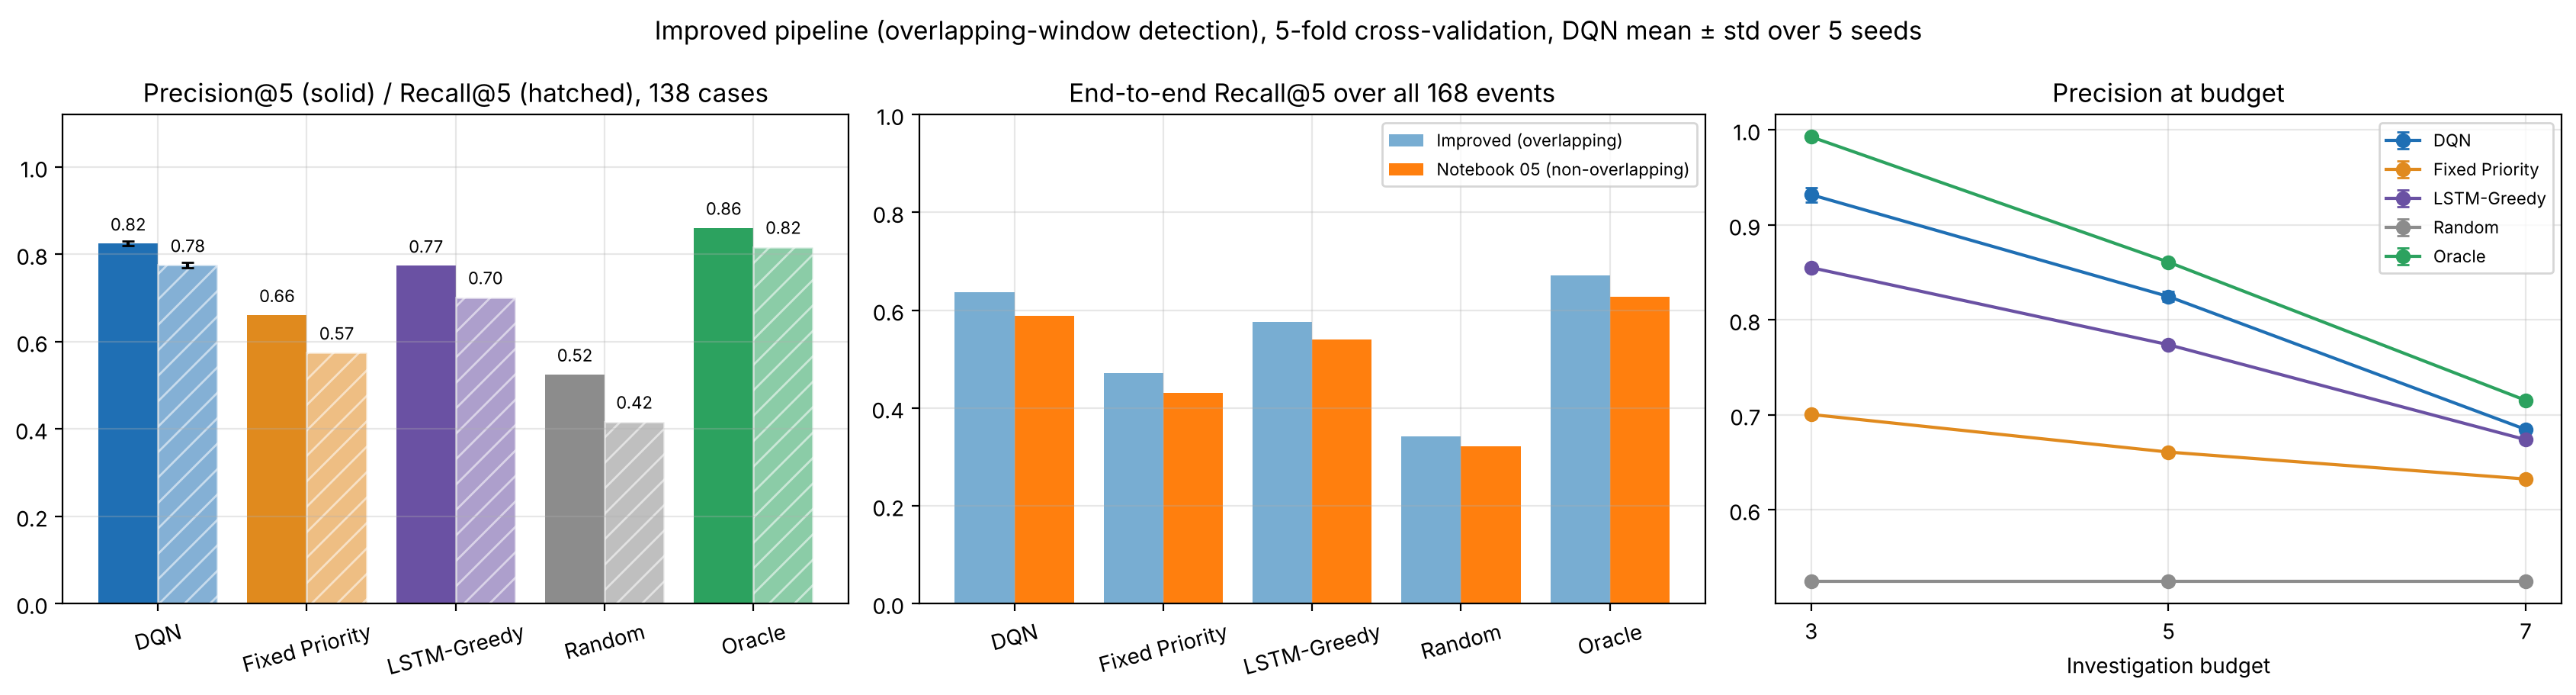

In [7]:
cols = {"DQN": "#1f6fb4", "Fixed Priority": "#e08a1e", "LSTM-Greedy": "#6a51a3", "Random": "#8c8c8c", "Oracle": "#2ca25f"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
s5 = summarise(CHOSEN).set_index("Method").loc[ORDER]; x = np.arange(len(ORDER))
ax[0].bar(x - 0.2, s5.Precision_at_5, 0.4, yerr=s5.Precision_at_5_std.where(s5.Precision_at_5_std > 0), capsize=3, color=[cols[m] for m in ORDER])
ax[0].bar(x + 0.2, s5.Recall_at_5, 0.4, yerr=s5.Recall_at_5_std.where(s5.Recall_at_5_std > 0), capsize=3, color=[cols[m] for m in ORDER], alpha=0.55, hatch="//", edgecolor="white")
for i, m in enumerate(ORDER):
    ax[0].text(i - 0.2, s5.loc[m, "Precision_at_5"] + 0.03, f"{s5.loc[m, 'Precision_at_5']:.2f}", ha="center", fontsize=8)
    ax[0].text(i + 0.2, s5.loc[m, "Recall_at_5"] + 0.03, f"{s5.loc[m, 'Recall_at_5']:.2f}", ha="center", fontsize=8)
ax[0].set_xticks(x, ORDER, rotation=15); ax[0].set_ylim(0, 1.12)
ax[0].set_title(f"Precision@5 (solid) / Recall@5 (hatched), {int(s5.loc['DQN','Cases'])} cases")
pv = e2e.pivot(index="Method", columns="Pipeline", values="E2E_Recall@5").loc[ORDER]
for j, c in enumerate(pv.columns):
    ax[1].bar(x + (j - 0.5) * 0.4, pv[c], 0.4, label=c, alpha=0.6 if j == 0 else 1.0)
ax[1].set_xticks(x, ORDER, rotation=15); ax[1].set_ylim(0, 1); ax[1].set_title("End-to-end Recall@5 over all 168 events"); ax[1].legend(fontsize=8)
for m in ORDER:
    d = sw[sw.Method == m].sort_values("Budget")
    ax[2].errorbar(d.Budget, d.Precision_at_5, yerr=d.Precision_at_5_std.where(d.Precision_at_5_std > 0), marker="o", capsize=3, label=m, color=cols[m])
ax[2].set_xticks([3, 5, 7]); ax[2].set_xlabel("Investigation budget"); ax[2].set_title("Precision at budget"); ax[2].legend(fontsize=8)
fig.suptitle("Improved pipeline (overlapping-window detection), 5-fold cross-validation, DQN mean ± std over 5 seeds")
save_show("22_improved_pipeline_results.png")

## 6. Save

In [8]:
import shutil; shutil.rmtree(IMP / "models", ignore_errors=True)
cov.to_csv(IMP / "event_detection_coverage.csv"); cov_tab.to_csv(IMP / "event_detection_coverage_summary.csv")
summarise(cv_plain).assign(Config=cv_plain.Config.iloc[0]).to_csv(IMP / "cv_overlapping_plain_budget5.csv", index=False)
summarise(cv_aug).assign(Config=cv_aug.Config.iloc[0]).to_csv(IMP / "cv_overlapping_augmented_budget5.csv", index=False)
paired_tests(CHOSEN).to_csv(IMP / "cv_chosen_tests_budget5.csv", index=False)
e2e.to_csv(IMP / "end_to_end_168_events.csv", index=False)
sw.to_csv(IMP / "cv_budget_sweep.csv", index=False); sw_t.to_csv(IMP / "cv_budget_sweep_tests.csv", index=False)
pd.concat([cv_plain, cv_aug, sweep[3], sweep[7]]).to_csv(IMP / "cv_per_case_results.csv", index=False)
json.dump({"stride": STRIDE, "threshold": THR, "windows_scored": int(len(starts)), "windows_detected": int(detected.sum()),
           "events_detected": len(CASE_EVENTS), "augmentation_top_k": 20,
           "inner_val_reward": {"plain": cv_plain.attrs["inner_val_reward"], "augmented": cv_aug.attrs["inner_val_reward"]},
           "chosen": CHOSEN.Config.iloc[0], "hyperparameters": HP, "seeds": SEEDS, "folds": K},
          open(IMP / "improved_config.json", "w"), indent=2)
for f in sorted(IMP.iterdir()): print(f"{f.name:45s} {f.stat().st_size/1e3:8.1f} KB")

cv_budget_sweep.csv                                2.4 KB
cv_budget_sweep_tests.csv                          1.1 KB
cv_chosen_tests_budget5.csv                        0.4 KB
cv_overlapping_augmented_budget5.csv               1.1 KB
cv_overlapping_plain_budget5.csv                   1.0 KB
cv_per_case_results.csv                          515.5 KB
end_to_end_168_events.csv                          1.1 KB
event_detection_coverage.csv                       5.9 KB
event_detection_coverage_summary.csv               0.1 KB
improved_config.json                               0.6 KB
